In [4]:
# Setup module: load packages
import QuantLib as ql
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pathlib import Path

In [5]:

# Setup module: load data
# Find the repository root
def find_repo_root():
    path = Path.cwd().resolve()

    for parent in [path, *path.parents]:
        if (parent / "requirements.txt").exists():
            return parent

    raise FileNotFoundError(
        "Repository root could not be found. "
        "Make sure you are running this notebook from within the repository."
    )


# Load data
repo_root = find_repo_root()
data_directory = repo_root / "data"

euribor_file = data_directory / "6M EURIBOR 20260820.xlsx"
ESTR_file = data_directory / "ESTR 20260820.xlsx"

ESTR_data = pd.read_excel(
    ESTR_file,
    sheet_name="Data",
    skiprows=0
)


Before we start with the term structure, we must set some global environment variables for QuantLib, such as the evaluation date.

In [6]:
# Set the global evaluationdate
ql.Settings.instance().evaluationDate = ql.Date(20,8,2026)

# Create an index object 
ESTR_curve_handle = ql.RelinkableYieldTermStructureHandle()     # empty curve handle, necessary to create the index object
ESTR_index        = ql.Eonia(ESTR_curve_handle)                 # index object, contains settings for the floating leg payments of ESTR swaps

## ESTR term structure
The collection of swap rates across maturities, such as 1 year, 2 years, 5 years, 10 years and 30 years, forms the €STR term structure. This term structure represents the market's pricing of risk-free interest rates across time and is used to construct the discount curve that underpins modern fixed income valuation and risk management.

For pricing and risk management, the most important curve is the zero curve, which represents rates applicable to a single cash flow occurring at a specific future date. This is unlike swap rates such as the 10-year ESTR swap rate, which are quoted market instruments representing multiple cash flows at once. Zero rates are not directly observable in the market and must be derived from the ESTR swap rates that we can observe in the market. The process of constructing zero rates from a set of financial instruments is called 'bootstrapping'. 

In this module, you'll learn how to construct an ESTR zero rate term structure using market observed swap rates. This module is not meant to explain the concept of bootstrapping, it will only show you how the bootstrapping process is done with QuantLib. If you do not yet understand what bootstrapping is, please search online or ask your colleague.

## ESTR zero-coupon term structure
In Quantlib, there are several build-in functions that do the bootstrapping for you based on a given interpolation method. The most important functions are ql.PiecewiseLinearZero() and ql.PiecewiseLogCubicDiscount(). We'll get into the details and differences of these functions later. Both these functions take three argumetns:
1. The curve date, which is the date you observe the quotes in the market
2. A list of financial instruments defined as 'helpers'. These helpers contain all information needed to bootstrap the curve
3. A day-count convention that specifies how to discount and compound cash flows using this curve object. For ESTR, this is Actual-365. 

We'll build the ESTR zero-coupon term structure from the following set of financial instruments:
- 1 deposit
- 32 ESTR swaps

In QuantLib, the instruments used to bootstrap a curve are defined as 'helper'-objects, literally meaning that they help you building the curve. We'll create our set of helpers step by step, starting with the deposit helper. But first, let's create an empty object where we can store all helpers, such that it can be passed to one of the bootstrap functions later on.


In [7]:
# Create an empty list of quotes and vector of helpers
ESTR_quotes  = []
ESTR_helpers = ql.RateHelperVector()

### Deposit rate helper
The first helper is the deposit helper, which is basically the anchor of the term structure. An ESTR deposit is an overnight deposit with a term of one day. You create the helper with the function ql.DepositRateHelper(), passing two argumetns: 
- the annual ESTR deposit rate, which is equal to the fixing of the date you construct your curve.
- the ESTR index object, containing all variables such as term and day count

In [8]:
# Current ESTR fixing:
current_ESTR_fixing = 0.0218                                            # pass the fixing as a numeric, not as percentage
current_ESTR_fixing_quote = ql.SimpleQuote(current_ESTR_fixing)         # wrap the quote in a simple quote object
current_ESTR_fixing_handle = ql.QuoteHandle(current_ESTR_fixing_quote)  # wrap the quote in a handle

ESTR_quotes.append(current_ESTR_fixing_quote)                           # add fixing to the list of quotes

In [9]:
# Create the deposit rate helper
deposit_helper = ql.DepositRateHelper(
    current_ESTR_fixing_handle,                                 # the quote handle pointing to our ESTR fixing
    ESTR_index                                                  # pass the index object such that all variables are passed based on the index settings
)

# Add the helper to the ESTR helper vector
ESTR_helpers.append(deposit_helper)

The deposit helper is the first helper in a series of helpers that will be used to bootstrap the zero-swap curve. Before we move on to another type of helpers, let's have a closer look at the deposit helper object and its methods. You can see that the maturity date is August 21, which is one day after the evaluation date that we've defined at the start of this module. 

In [10]:
print(f"""
The quote value of the deposit is: {deposit_helper.quote().value()}
The maturity date of the deposit is: {deposit_helper.maturityDate()}
""")


The quote value of the deposit is: 0.0218
The maturity date of the deposit is: August 21st, 2026



### Swap rate helpers
The remainder of the helpers are swap rate helpers. More specific: OIS rate helpers, ql.OISRateHelper(). OIS stands for 'Overnight Index Swap', which is exactly what an ESTR swap is. 

The ql.OISRateHelper() takes four arguments:
- settlementdays: the number of days it takes to settle a swap contract. For ESTR swaps, this is usually 2 days (T+2 settlement). This argument is passed as a numeric.
- tenor: the term to maturity of the swap. This argument is passed as a ql.Period(), for example ql.Period(1, ql.Weeks)
- a quote handle: a handle object pointing to the market swap rate
- an index object: by linking the helper to an index, the helper can use all undefined parameters, such as day count, from the index. By passing the index, you'll automatically ensure that these other parameters are set correctly.

We'll create the OISRateHelpers using our market rates from the data 'data\ESTR 20260820.xslx'. The data was loaded at the start of the module. Let's have a look at the first row of the data and see how we can create the first OISRateHelper.

In [11]:
ESTR_data.iloc[0]

Term                 1 WK
Market Rate          2.19
Year Fraction    0.019231
Name: 0, dtype: object

In [12]:
# specify parameters for the swap helper
tenor = ql.Period(1, ql.Weeks)                                  # tenor of the first swap in our data set is one week
quote = 2.18905 / 100                                           # your quote should be a numeric, not a whole percentage -> divide by 100
quote_object = ql.SimpleQuote(quote)                            # wrap it into a quote object
quote_handle = ql.QuoteHandle(quote_object)                     # wrap it into a quote handle

settlementDays = 2                                              # by default, ESTR swaps have T+2 settlement

In [13]:
swap_helper = ql.OISRateHelper(
    settlementDays,                                             # the number of settlement days for your swap instrument
    tenor,                                                      # the tenor, i.e. the time to maturity
    quote_handle,                                               # the quote wrapped into a quote handle object
    ESTR_index                                                  # the ESTR index object containing all other parameters for ESTR swaps
)


In [14]:
print(f"""
The quote value of the swap is: {swap_helper.quote().value()}
The maturity date of the swap is: {swap_helper.maturityDate()}
""")


The quote value of the swap is: 0.0218905
The maturity date of the swap is: August 31st, 2026



Let's have a closer look at the maturity date of our helper object to get a good understanding of how this date is defined. 
1. The global evaluation date was set on August 20 at the start of this session. That means that if we create a new helper, it's created as of August 20th. The settlement days parameter was set to 2, which means the swap is accruing interest 2 days after you enter the swap. Taking into account that August 22 and 23th were weekend days, T+2 is August 24th. At that date, the swap starts accruing interest. 
2. From that date onwards, we take the term of the swap, which is one week. Adding one week to August 24th is indeed August 31st, which is the maturity date of this swap. See the yellow circles below.

<img src="pictures/calendar august 2026.png">

### Create all other swap rate helpers
Now we know how to create one swap rate helper. Let's do this for all ESTR swaps in our ESTR database.


In [15]:
# Create all ESTR helpers
for idx,row in ESTR_data.iterrows():
    # Settlement days
    settlementDays = 2

    # Tenor
    # Extract the tenor from the dataset. The tenor is given as string and needs some adjustment to be converted to a quantlib period
    [tenor_numeric, period] = row['Term'].split()
    tenor_numeric = int(tenor_numeric)
    if period == "WK":
        tenor = ql.Period(tenor_numeric, ql.Weeks)
    elif period == "MO": 
        tenor = ql.Period(tenor_numeric, ql.Months)
    elif period == "YR":
        tenor = ql.Period(tenor_numeric, ql.Years)
    else:
        raise ValueError(f"{row['Term']} not specified")

    # Quote handle
    quote = float(row['Market Rate']) / 100
    quote_object = ql.SimpleQuote(quote)
    quote_handle = ql.QuoteHandle(quote_object)

    # Create a new swap helper:
    swap_helper = ql.OISRateHelper(
        settlementDays,                                             # the number of settlement days for your swap instrument
        tenor,                                                      # the tenor, i.e. the time to maturity
        quote_handle,                                               # the quote wrapped into a quote handle object
        ESTR_index                                                  # the ESTR index object containing all other parameters for ESTR swaps
    )
    
    # Add the helper to the ESTR helper vector
    ESTR_helpers.append(swap_helper)
    

## Bootstrapping the ESTR term structure
We've created our vector of helpers based on rates observed in the market. The next step is to bootstrap the ESTR term structure from this set of helpers. Again, we'll not go into the details of the bootstrapping process. Here we'll focus on how to apply QuantLib to bootstrap automatically.

There are several methods to bootstrap curves using QuantLib, where the difference lies in the interpolation methodology. For the first example, we'll look at ql.PiecewiseLogCubicDiscount(). This function interpolates the ... (replace). 

In [16]:
# Bootstrap the ESTR curve

# Set the curvedate to our current evaluation date
curveDate = ql.Settings.instance().evaluationDate

# Apply the PiecewiseLogCubicDiscount() function on our set of helpers
ESTR_curve = ql.PiecewiseLogCubicDiscount(
    curveDate,                                                      # the date of the observed market rates
    ESTR_helpers,                                                   # the vector containing our ESTR helpers and the deposit helper
    ql.Actual365Fixed()                                             # the convention for the curve
)

# Enable extrapolation to obtain zero rates outside the maturity range of our helpers
ESTR_curve.enableExtrapolation()

In [17]:
ESTR_curve.zeroRate(0.08, ql.Compounded, ql.Annual).rate()

0.02277080060355008

Text(0, 0.5, 'Discount factor')

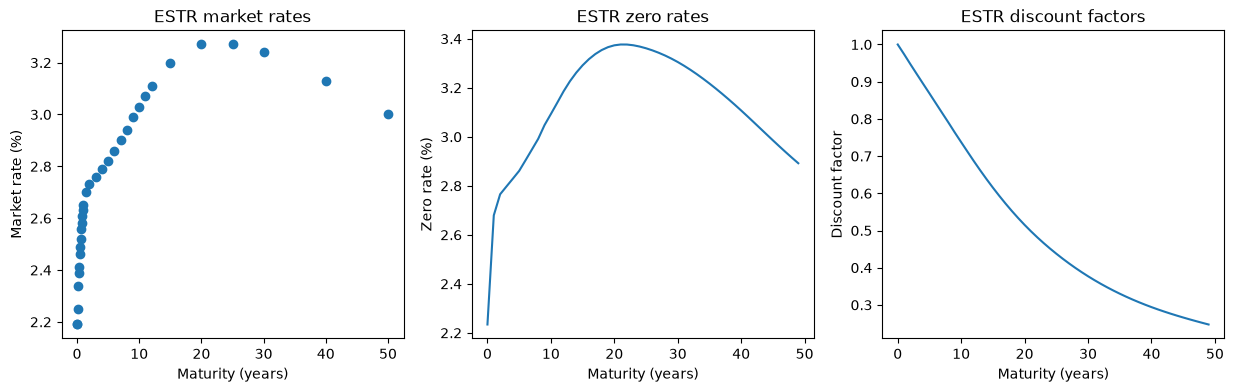

In [18]:
# Create the plot figure
fig, axes = plt.subplots(nrows=1,ncols=3, figsize=(15,4))

# Plot the market rates directly from the data
axes[0].plot(ESTR_data['Year Fraction'], ESTR_data['Market Rate'], marker='o', linestyle='')

# Plot the zero rates
max_maturity = int(max(ESTR_data['Year Fraction']))
x_values = range(max_maturity)
axes[1].plot(x_values, [ESTR_curve.zeroRate(x, ql.Compounded, ql.Annual).rate() * 100 for x in range(max_maturity)])

# Plot the discount factors, use max_maturity from the zero rates
axes[2].plot(x_values, [ESTR_curve.discount(x) for x in range(max_maturity)])

# Finish the plot by setting titles and axis titles
axes[0].set_title('ESTR market rates')
axes[1].set_title('ESTR zero rates')
axes[2].set_title('ESTR discount factors')

axes[0].set_xlabel('Maturity (years)')
axes[0].set_ylabel('Market rate (%)')
axes[1].set_xlabel('Maturity (years)')
axes[1].set_ylabel('Zero rate (%)')
axes[2].set_xlabel('Maturity (years)')
axes[2].set_ylabel('Discount factor')

## Exercise
There are other bootstrapping methods available in QuantLib. For example, ql.PiecewiseLinearZero(). Use the previously created set of helpers and construct your own ESTR curve with the piecewise linear zero method. Then add the zero rates and the discount factors to the plots to see the impact of the method on the obtained zero rates. 

Once finished, search online why there are different methods and how to pick the method suitable for your application. 

In [19]:
# Your implementation here

# Forward rates
In our ESTR term structure, we can observe market rates such as the overnight rate, the 5-year swap rate, and the 10-year swap rate. But what if we want to know the interest rate implied for a period between year 4 and year 5?

This question is important when valuing the floating leg of an interest rate swap, as we need an estimate of future floating-rate payments.

For example, consider the final floating-leg payment of a 10-year interest rate swap. From the market, we observe the 10-year swap rate, which represents the fixed rate exchanged over the life of the swap. However, the final floating payment is based on a one-year interest rate that applies from year 9 to year 10. This rate is not directly quoted in the market. Instead, it must be derived from the yield curve. This is where forward rates come into play.

A forward rate is the interest rate implied by the current yield curve for a future borrowing or lending period. For example, the 1-year forward rate starting in 9 years (often referred to as the 1y9y forward rate) represents the interest rate implied today for a one-year loan that begins 9 years from now.

The collection of forward rates across all future periods is known as the forward curve. It can be interpreted as the set of future interest rates implied by today's market prices and is used to project the future floating cash flows of an interest rate swap.

Quantlib allows you to compute the forward rate directly from the interest rate object. Below you can see how to compute the 1y9y forward rate from the ESTR_curve using .forwardRate().

In [20]:
# Extract the 1y9y forward rate from our ESTR curve
startDate = ql.Settings.instance().evaluationDate + ql.Period(9, ql.Years) # 9 years from now
endDate   = startDate + ql.Period(1, ql.Years) # 1 year rate

forward_rate = ESTR_curve.forwardRate(
    startDate,
    endDate,
    ql.Actual365Fixed(),
    ql.Compounded
).rate()

print(f"""
The 1y9y forward rate is {round(forward_rate*100,2)}%
""")


The 1y9y forward rate is 3.5%



## Exercise
Now try to obtain the 2y2y forward rate and explain what this rate represents.

In [21]:
# your implementation here

# Forward surface
Our market rates, zero rates, and discount factors are one-dimensional: they depend only on the maturity. For example, we can speak about the 10-year zero rate or the 10-year discount factor.

Forward rates, however, are two-dimensional: they depend on both a start date and a forward period. As a result, it is not sufficient to speak about a "9-year forward rate". Instead, both dimensions must be specified.

For example, consider the 1-year forward rate starting in 9 years. This rate applies to a one-year loan that begins 9 years from today and ends 10 years from today. In this case:

- The forward start date is 9 years from now.
- The forward period (or tenor) is 1 year.

Because forward rates require both a start date and a tenor, we can think of them as forming a two-dimensional surface rather than a single curve.

# Forward curves
Forward curves are obtained by fixing the forward period (tenor) and plotting the corresponding forward rates against their forward start dates.

For example, the 1-year forward curve consists of all 1-year forward rates, such as the 1-year rate starting today, the 1-year rate starting in 1 year, the 1-year rate starting in 2 years, and so on. Similarly, the 5-year forward curve consists of all 5-year forward rates for different forward start dates.

In other words, a forward curve is a one-dimensional slice of the two-dimensional forward-rate surface, where the tenor is fixed and only the forward start date varies.

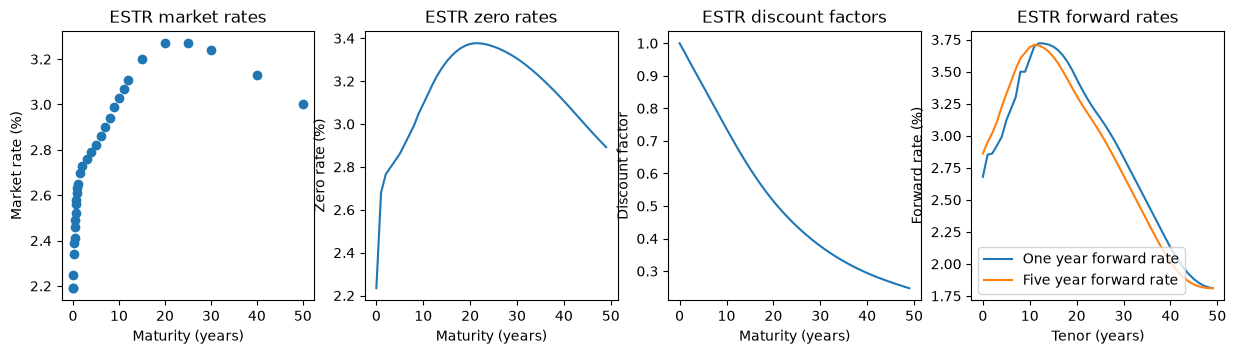

In [22]:
forward_rates_1 = []
forward_rates_5 = []

# Generate forward rates 
for n in range(50):
    startDate = curveDate + ql.Period(n, ql.Years)
    endDate_1 = startDate + ql.Period(1, ql.Years)
    endDate_5 = startDate + ql.Period(5, ql.Years)

    fwd_1 = ESTR_curve.forwardRate(startDate, endDate_1, ql.Actual365Fixed(), ql.Compounded, ql.Annual)
    fwd_5 = ESTR_curve.forwardRate(startDate, endDate_5, ql.Actual365Fixed(), ql.Compounded, ql.Annual)

    forward_rates_1.append(fwd_1)
    forward_rates_5.append(fwd_5)

# plot next to our market, zero and discount curves:
fig, axes = plt.subplots(nrows=1,ncols=4, figsize=(15,3.5))

# Plot the market rates directly from the data
axes[0].plot(ESTR_data['Year Fraction'], ESTR_data['Market Rate'], marker='o', linestyle='')

# Plot the zero rates
max_maturity = int(max(ESTR_data['Year Fraction']))
x_values = range(max_maturity)
axes[1].plot(x_values, [ESTR_curve.zeroRate(x, ql.Compounded, ql.Annual).rate() * 100 for x in range(max_maturity)])

# Plot the discount factors, use max_maturity from the zero rates
axes[2].plot(x_values, [ESTR_curve.discount(x) for x in range(max_maturity)])

# Plot the forward curves
axes[3].plot(range(50), [r.rate() * 100 for r in forward_rates_1], label='One year forward rate')
axes[3].plot(range(50), [r.rate() * 100 for r in forward_rates_5], label='Five year forward rate')

# Finish the plot by setting titles and axis titles
axes[0].set_title('ESTR market rates')
axes[1].set_title('ESTR zero rates')
axes[2].set_title('ESTR discount factors')
axes[3].set_title('ESTR forward rates')


axes[0].set_xlabel('Maturity (years)')
axes[0].set_ylabel('Market rate (%)')
axes[1].set_xlabel('Maturity (years)')
axes[1].set_ylabel('Zero rate (%)')
axes[2].set_xlabel('Maturity (years)')
axes[2].set_ylabel('Discount factor')
axes[3].set_xlabel('Tenor (years)')
axes[3].set_ylabel('Forward rate (%)')

axes[3].legend()


## Interpretation of the forward curves
What does this graph tells us? One thing that can be derived is, for example, that based on current market quotes the implied 5-year rate in 10 years from now is approximately 3.70%. 

Furthermore, we can relate the forward rates to the zero rates. We see that the zero rates rise from roughly 2.2% at the short end to a peak of about 3.4% around 20 years. Because the zero rate rises, the future period rates must generally be above the corresponding zero rates. This explains why the forward curves rise to approximately 3.7%. 
